In [1]:
# Cell 1: ElasticNet — Imports and Project Setup

import json
import time
import platform
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from pathlib import Path
from scipy.stats import pearsonr

from google.colab import drive

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    median_absolute_error,
    explained_variance_score,
    max_error,
)

# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ------------------------------------------------------------
# 2. Mount Google Drive
# ------------------------------------------------------------

drive.mount("/content/drive")

# ------------------------------------------------------------
# 3. Project paths
# ------------------------------------------------------------

PROJECT_PATH = Path(
    "/content/drive/MyDrive/Solar_Wind_Project"
)

ML_PATH = PROJECT_PATH / "ML"

FLAT_DATA_PATH = ML_PATH / "data_flat"
ENGINEERED_DATA_PATH = ML_PATH / "data_engineered"

LINEAR_PATH = ML_PATH / "Linear"
ELASTICNET_PATH = LINEAR_PATH / "ElasticNet"

RESULTS_PATH = ELASTICNET_PATH
FIGURES_PATH = ELASTICNET_PATH / "figures"

RESULTS_PATH.mkdir(parents=True, exist_ok=True)
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 4. ElasticNet configuration
# ------------------------------------------------------------

MODEL_NAME = "ElasticNet"
RESULT_PREFIX = "elasticnet"

ALPHA_GRID = [0.001, 0.01, 0.1, 1.0]
L1_RATIO_GRID = [0.1, 0.5, 0.9]

MAX_ITER = 2000
TOL = 1e-2

# Keep the benchmark protocol consistent with previous models.
WARMUP_RUNS = 2
INFERENCE_REPEATS = 10

FIGURE_DPI = 300

# ------------------------------------------------------------
# 5. Verify paths and environment
# ------------------------------------------------------------

print("ElasticNet Regression setup completed.")
print(f"Project path:      {PROJECT_PATH}")
print(f"Flat data path:    {FLAT_DATA_PATH}")
print(f"Engineered path:   {ENGINEERED_DATA_PATH}")
print(f"ElasticNet folder: {ELASTICNET_PATH}")
print(f"Figures folder:    {FIGURES_PATH}")

print(f"\nRandom state:      {RANDOM_STATE}")
print(f"Alpha grid:        {ALPHA_GRID}")
print(f"L1 ratio grid:     {L1_RATIO_GRID}")
print(f"Maximum iterations:{MAX_ITER}")
print(f"Tolerance:         {TOL}")
print(f"Warm-up runs:      {WARMUP_RUNS}")
print(f"Timed repetitions: {INFERENCE_REPEATS}")
print(f"Scikit-learn:      {sklearn.__version__}")

assert FLAT_DATA_PATH.exists(), (
    f"Flat dataset directory not found: {FLAT_DATA_PATH}"
)

assert ENGINEERED_DATA_PATH.exists(), (
    f"Engineered dataset directory not found: "
    f"{ENGINEERED_DATA_PATH}"
)

print("\nDataset directories verified successfully.")
print("Cell 1 completed successfully.")

Mounted at /content/drive
ElasticNet Regression setup completed.
Project path:      /content/drive/MyDrive/Solar_Wind_Project
Flat data path:    /content/drive/MyDrive/Solar_Wind_Project/ML/data_flat
Engineered path:   /content/drive/MyDrive/Solar_Wind_Project/ML/data_engineered
ElasticNet folder: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/ElasticNet
Figures folder:    /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/ElasticNet/figures

Random state:      42
Alpha grid:        [0.001, 0.01, 0.1, 1.0]
L1 ratio grid:     [0.1, 0.5, 0.9]
Maximum iterations:2000
Tolerance:         0.01
Warm-up runs:      2
Timed repetitions: 10
Scikit-learn:      1.6.1

Dataset directories verified successfully.
Cell 1 completed successfully.


In [2]:
# Cell 2: Load and Verify Data

# ------------------------------------------------------------
# 1. Load FLAT representation
# ------------------------------------------------------------

X_train_flat = np.load(
    FLAT_DATA_PATH / "X_train.npy"
).astype(np.float32, copy=False)

X_val_flat = np.load(
    FLAT_DATA_PATH / "X_val.npy"
).astype(np.float32, copy=False)

X_test_flat = np.load(
    FLAT_DATA_PATH / "X_test.npy"
).astype(np.float32, copy=False)

y_train_flat = np.load(
    FLAT_DATA_PATH / "y_train.npy"
).reshape(-1).astype(np.float32, copy=False)

y_val_flat = np.load(
    FLAT_DATA_PATH / "y_val.npy"
).reshape(-1).astype(np.float32, copy=False)

y_test_flat = np.load(
    FLAT_DATA_PATH / "y_test.npy"
).reshape(-1).astype(np.float32, copy=False)


# ------------------------------------------------------------
# 2. Load ENGINEERED representation
# ------------------------------------------------------------

X_train_eng = np.load(
    ENGINEERED_DATA_PATH / "X_train.npy"
).astype(np.float32, copy=False)

X_val_eng = np.load(
    ENGINEERED_DATA_PATH / "X_val.npy"
).astype(np.float32, copy=False)

X_test_eng = np.load(
    ENGINEERED_DATA_PATH / "X_test.npy"
).astype(np.float32, copy=False)

y_train_eng = np.load(
    ENGINEERED_DATA_PATH / "y_train.npy"
).reshape(-1).astype(np.float32, copy=False)

y_val_eng = np.load(
    ENGINEERED_DATA_PATH / "y_val.npy"
).reshape(-1).astype(np.float32, copy=False)

y_test_eng = np.load(
    ENGINEERED_DATA_PATH / "y_test.npy"
).reshape(-1).astype(np.float32, copy=False)


# ------------------------------------------------------------
# 3. Verify expected feature shapes
# ------------------------------------------------------------

expected_flat_shapes = {
    "train": (97897, 1008),
    "val": (20978, 1008),
    "test": (20979, 1008),
}

expected_eng_shapes = {
    "train": (97897, 112),
    "val": (20978, 112),
    "test": (20979, 112),
}

assert X_train_flat.shape == expected_flat_shapes["train"]
assert X_val_flat.shape == expected_flat_shapes["val"]
assert X_test_flat.shape == expected_flat_shapes["test"]

assert X_train_eng.shape == expected_eng_shapes["train"]
assert X_val_eng.shape == expected_eng_shapes["val"]
assert X_test_eng.shape == expected_eng_shapes["test"]


# ------------------------------------------------------------
# 4. Verify target shapes
# ------------------------------------------------------------

assert y_train_flat.shape == (97897,)
assert y_val_flat.shape == (20978,)
assert y_test_flat.shape == (20979,)

assert y_train_eng.shape == (97897,)
assert y_val_eng.shape == (20978,)
assert y_test_eng.shape == (20979,)


# ------------------------------------------------------------
# 5. Verify targets match between representations
# ------------------------------------------------------------

np.testing.assert_array_equal(y_train_flat, y_train_eng)
np.testing.assert_array_equal(y_val_flat, y_val_eng)
np.testing.assert_array_equal(y_test_flat, y_test_eng)


# ------------------------------------------------------------
# 6. Verify all arrays contain finite values
# ------------------------------------------------------------

arrays_to_check = {
    "X_train_flat": X_train_flat,
    "X_val_flat": X_val_flat,
    "X_test_flat": X_test_flat,
    "y_train_flat": y_train_flat,
    "y_val_flat": y_val_flat,
    "y_test_flat": y_test_flat,
    "X_train_eng": X_train_eng,
    "X_val_eng": X_val_eng,
    "X_test_eng": X_test_eng,
    "y_train_eng": y_train_eng,
    "y_val_eng": y_val_eng,
    "y_test_eng": y_test_eng,
}

for name, array in arrays_to_check.items():
    assert np.isfinite(array).all(), (
        f"Non-finite values found in {name}"
    )


# ------------------------------------------------------------
# 7. Verification summary
# ------------------------------------------------------------

print("DATA VERIFICATION PASSED")

print("\nFLAT REPRESENTATION")
print("Train      :", X_train_flat.shape, y_train_flat.shape)
print("Validation :", X_val_flat.shape, y_val_flat.shape)
print("Test       :", X_test_flat.shape, y_test_flat.shape)

print("\nENGINEERED REPRESENTATION")
print("Train      :", X_train_eng.shape, y_train_eng.shape)
print("Validation :", X_val_eng.shape, y_val_eng.shape)
print("Test       :", X_test_eng.shape, y_test_eng.shape)

print("\nTarget arrays match between both representations.")
print("All arrays contain finite values.")
print("\nCell 2 completed successfully.")

DATA VERIFICATION PASSED

FLAT REPRESENTATION
Train      : (97897, 1008) (97897,)
Validation : (20978, 1008) (20978,)
Test       : (20979, 1008) (20979,)

ENGINEERED REPRESENTATION
Train      : (97897, 112) (97897,)
Validation : (20978, 112) (20978,)
Test       : (20979, 112) (20979,)

Target arrays match between both representations.
All arrays contain finite values.

Cell 2 completed successfully.


In [3]:
# Cell 3: ElasticNet Model Configuration

MODEL_NAME = "ElasticNet"

# Hyperparameter search grid
ALPHA_GRID = [0.001, 0.01, 0.1, 1.0]
L1_RATIO_GRID = [0.1, 0.5, 0.9]

# Convergence settings from your reference code
MAX_ITER = 2000
TOL = 1e-2

# Inference benchmark protocol — consistent with previous models
WARMUP_RUNS = 2
INFERENCE_REPEATS = 10

elasticnet_config = {
    "model": MODEL_NAME,
    "alpha_grid": ALPHA_GRID,
    "l1_ratio_grid": L1_RATIO_GRID,
    "fit_intercept": True,
    "max_iter": MAX_ITER,
    "tolerance": TOL,
    "selection": "random",
    "random_state": RANDOM_STATE,
    "selection_metric": "validation_RMSE",
    "scaling": "StandardScaler fitted on training data only",
    "inference_warmup_runs": WARMUP_RUNS,
    "inference_timing_runs": INFERENCE_REPEATS,
}

# Save configuration
config_path = RESULTS_PATH / "elasticnet_configuration.json"

with open(config_path, "w") as f:
    json.dump(elasticnet_config, f, indent=4)

# Display configuration
print("ELASTICNET MODEL CONFIGURATION")
print("-" * 60)

for key, value in elasticnet_config.items():
    print(f"{key}: {value}")

print("\nFeature information:")
print(f"Flat features       : {X_train_flat.shape[1]}")
print(f"Engineered features : {X_train_eng.shape[1]}")

total_combinations = len(ALPHA_GRID) * len(L1_RATIO_GRID)

print(f"\nCombinations per representation: {total_combinations}")
print(f"Total combinations across both representations: {2 * total_combinations}")
print(f"\nConfiguration saved to: {config_path}")
print("\nCell 3 completed successfully.")

ELASTICNET MODEL CONFIGURATION
------------------------------------------------------------
model: ElasticNet
alpha_grid: [0.001, 0.01, 0.1, 1.0]
l1_ratio_grid: [0.1, 0.5, 0.9]
fit_intercept: True
max_iter: 2000
tolerance: 0.01
selection: random
random_state: 42
selection_metric: validation_RMSE
scaling: StandardScaler fitted on training data only
inference_warmup_runs: 2
inference_timing_runs: 10

Feature information:
Flat features       : 1008
Engineered features : 112

Combinations per representation: 12
Total combinations across both representations: 24

Configuration saved to: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/ElasticNet/elasticnet_configuration.json

Cell 3 completed successfully.


In [4]:
# Cell 4: Train ElasticNet — Flat Representation

print("TRAINING ELASTICNET — FLAT REPRESENTATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Standardize flat features
# Fit scaler ONLY on training data.
# ------------------------------------------------------------

flat_scaler = StandardScaler()

print("\nFitting StandardScaler on flat training data...")

X_train_flat_scaled = flat_scaler.fit_transform(
    X_train_flat
).astype(np.float32, copy=False)

X_val_flat_scaled = flat_scaler.transform(
    X_val_flat
).astype(np.float32, copy=False)

X_test_flat_scaled = flat_scaler.transform(
    X_test_flat
).astype(np.float32, copy=False)

print("Scaling complete.")
print("Train      :", X_train_flat_scaled.shape)
print("Validation :", X_val_flat_scaled.shape)
print("Test       :", X_test_flat_scaled.shape)

# ------------------------------------------------------------
# 2. Prepare hyperparameter search
# ------------------------------------------------------------

flat_validation_results = []

best_flat_alpha = None
best_flat_l1_ratio = None
best_flat_val_rmse = np.inf
best_flat_model = None
best_flat_train_time = None

total_combinations = len(ALPHA_GRID) * len(L1_RATIO_GRID)
combination_number = 0

flat_tuning_start = time.perf_counter()

print("\nSelecting alpha and l1_ratio using VALIDATION RMSE...")
print(f"Total combinations: {total_combinations}")
print("=" * 70)

# ------------------------------------------------------------
# 3. Grid search
# ------------------------------------------------------------

for alpha in ALPHA_GRID:
    for l1_ratio in L1_RATIO_GRID:
        combination_number += 1

        print(
            f"\nCombination {combination_number}/{total_combinations}",
            flush=True,
        )
        print(
            f"alpha={alpha} | l1_ratio={l1_ratio}",
            flush=True,
        )

        model = ElasticNet(
            alpha=alpha,
            l1_ratio=l1_ratio,
            fit_intercept=True,
            max_iter=MAX_ITER,
            tol=TOL,
            random_state=RANDOM_STATE,
            selection="random",
        )

        # Train and time this candidate.
        start_time = time.perf_counter()

        model.fit(
            X_train_flat_scaled,
            y_train_flat,
        )

        training_time = time.perf_counter() - start_time

        # Select using validation RMSE.
        val_predictions = model.predict(X_val_flat_scaled)

        val_rmse = float(
            np.sqrt(
                mean_squared_error(
                    y_val_flat,
                    val_predictions,
                )
            )
        )

        # Record coefficient sparsity.
        nonzero_coefficients = int(
            np.count_nonzero(model.coef_)
        )
        zero_coefficients = int(
            model.coef_.size - nonzero_coefficients
        )

        flat_validation_results.append({
            "alpha": float(alpha),
            "l1_ratio": float(l1_ratio),
            "validation_rmse": val_rmse,
            "training_time_seconds": float(training_time),
            "nonzero_coefficients": nonzero_coefficients,
            "zero_coefficients": zero_coefficients,
            "converged_within_max_iter": (
                int(model.n_iter_) < MAX_ITER
            ),
            "n_iter": int(model.n_iter_),
        })

        print(
            f"Validation RMSE={val_rmse:.4f} nT | "
            f"Non-zero={nonzero_coefficients} | "
            f"Zero={zero_coefficients} | "
            f"Iterations={model.n_iter_} | "
            f"Time={training_time:.2f} s",
            flush=True,
        )

        # Keep the best candidate using validation RMSE only.
        if val_rmse < best_flat_val_rmse:
            best_flat_val_rmse = val_rmse
            best_flat_alpha = alpha
            best_flat_l1_ratio = l1_ratio
            best_flat_model = model
            best_flat_train_time = training_time

            print(">>> New best validation model", flush=True)

flat_tuning_duration = time.perf_counter() - flat_tuning_start

# ------------------------------------------------------------
# 4. Store the selected model
# ------------------------------------------------------------

if best_flat_model is None:
    raise RuntimeError("Flat ElasticNet search did not select a model.")

elasticnet_flat_model = best_flat_model
flat_training_duration = float(best_flat_train_time)

flat_validation_predictions = elasticnet_flat_model.predict(
    X_val_flat_scaled
)

flat_nonzero_coefficients = int(
    np.count_nonzero(elasticnet_flat_model.coef_)
)
flat_zero_coefficients = int(
    elasticnet_flat_model.coef_.size - flat_nonzero_coefficients
)

# ------------------------------------------------------------
# 5. Save the complete search results
# ------------------------------------------------------------

flat_validation_results_df = pd.DataFrame(flat_validation_results)

flat_search_path = RESULTS_PATH / "elasticnet_flat_alpha_search.csv"

flat_validation_results_df.to_csv(
    flat_search_path,
    index=False,
)

# ------------------------------------------------------------
# 6. Display results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("BEST FLAT ELASTICNET MODEL")
print("=" * 70)

print("Selected alpha          :", best_flat_alpha)
print("Selected l1_ratio       :", best_flat_l1_ratio)
print(f"Best validation RMSE    : {best_flat_val_rmse:.4f} nT")
print(f"Selected fit duration   : {flat_training_duration:.3f} s")
print(f"Total search duration   : {flat_tuning_duration:.3f} s")
print(f"Total coefficients      : {elasticnet_flat_model.coef_.size}")
print(f"Non-zero coefficients   : {flat_nonzero_coefficients}")
print(f"Zero coefficients       : {flat_zero_coefficients}")
print(f"Iterations used         : {elasticnet_flat_model.n_iter_}")

print(f"\nSearch results saved to: {flat_search_path}")
print("\nCell 4 completed successfully.")

TRAINING ELASTICNET — FLAT REPRESENTATION

Fitting StandardScaler on flat training data...
Scaling complete.
Train      : (97897, 1008)
Validation : (20978, 1008)
Test       : (20979, 1008)

Selecting alpha and l1_ratio using VALIDATION RMSE...
Total combinations: 12

Combination 1/12
alpha=0.001 | l1_ratio=0.1
Validation RMSE=9.4638 nT | Non-zero=999 | Zero=9 | Iterations=2000 | Time=269.87 s
>>> New best validation model

Combination 2/12
alpha=0.001 | l1_ratio=0.5


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.918e+06, tolerance: 4.403e+05
  model = cd_fast.enet_coordinate_descent(


Validation RMSE=9.4644 nT | Non-zero=954 | Zero=54 | Iterations=2000 | Time=266.35 s

Combination 3/12
alpha=0.001 | l1_ratio=0.9


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.316e+05, tolerance: 4.403e+05
  model = cd_fast.enet_coordinate_descent(


Validation RMSE=9.4644 nT | Non-zero=839 | Zero=169 | Iterations=2000 | Time=248.05 s

Combination 4/12
alpha=0.01 | l1_ratio=0.1


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.963e+05, tolerance: 4.403e+05
  model = cd_fast.enet_coordinate_descent(


Validation RMSE=9.4212 nT | Non-zero=877 | Zero=131 | Iterations=348 | Time=43.72 s
>>> New best validation model

Combination 5/12
alpha=0.01 | l1_ratio=0.5
Validation RMSE=9.4116 nT | Non-zero=634 | Zero=374 | Iterations=258 | Time=29.04 s
>>> New best validation model

Combination 6/12
alpha=0.01 | l1_ratio=0.9
Validation RMSE=9.4056 nT | Non-zero=480 | Zero=528 | Iterations=218 | Time=20.76 s
>>> New best validation model

Combination 7/12
alpha=0.1 | l1_ratio=0.1
Validation RMSE=9.4061 nT | Non-zero=637 | Zero=371 | Iterations=50 | Time=8.17 s

Combination 8/12
alpha=0.1 | l1_ratio=0.5
Validation RMSE=9.3836 nT | Non-zero=379 | Zero=629 | Iterations=46 | Time=3.11 s
>>> New best validation model

Combination 9/12
alpha=0.1 | l1_ratio=0.9
Validation RMSE=9.3624 nT | Non-zero=291 | Zero=717 | Iterations=46 | Time=2.90 s
>>> New best validation model

Combination 10/12
alpha=1.0 | l1_ratio=0.1
Validation RMSE=9.3615 nT | Non-zero=625 | Zero=383 | Iterations=19 | Time=1.86 s
>>> New b

In [5]:
# Cell 5: Train ElasticNet — Engineered Representation

print("=" * 70)
print("TRAINING ELASTICNET — ENGINEERED REPRESENTATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Standardize engineered features
# Fit scaler ONLY on training data.
# ------------------------------------------------------------

engineered_scaler = StandardScaler()

print("\nFitting StandardScaler on engineered training data...")

X_train_eng_scaled = engineered_scaler.fit_transform(
    X_train_eng
).astype(np.float32, copy=False)

X_val_eng_scaled = engineered_scaler.transform(
    X_val_eng
).astype(np.float32, copy=False)

X_test_eng_scaled = engineered_scaler.transform(
    X_test_eng
).astype(np.float32, copy=False)

print("Scaling complete.")
print("Train      :", X_train_eng_scaled.shape)
print("Validation :", X_val_eng_scaled.shape)
print("Test       :", X_test_eng_scaled.shape)

# ------------------------------------------------------------
# 2. Prepare hyperparameter search
# ------------------------------------------------------------

engineered_validation_results = []

best_engineered_val_rmse = np.inf
best_engineered_alpha = None
best_engineered_l1_ratio = None
best_engineered_model = None
best_engineered_train_time = None

total_combinations = len(ALPHA_GRID) * len(L1_RATIO_GRID)
combination_number = 0

engineered_tuning_start = time.perf_counter()

print("\nSelecting alpha and l1_ratio using VALIDATION RMSE...")
print(f"Total combinations: {total_combinations}")
print("=" * 70)

# ------------------------------------------------------------
# 3. Grid search
# ------------------------------------------------------------

for alpha in ALPHA_GRID:
    for l1_ratio in L1_RATIO_GRID:
        combination_number += 1

        print(
            f"\nCombination {combination_number}/{total_combinations}",
            flush=True,
        )
        print(
            f"alpha={alpha} | l1_ratio={l1_ratio}",
            flush=True,
        )

        model = ElasticNet(
            alpha=alpha,
            l1_ratio=l1_ratio,
            fit_intercept=True,
            max_iter=MAX_ITER,
            tol=TOL,
            random_state=RANDOM_STATE,
            selection="random",
        )

        # Train and time this candidate.
        start_time = time.perf_counter()

        model.fit(
            X_train_eng_scaled,
            y_train_eng,
        )

        training_time = time.perf_counter() - start_time

        # Evaluate on validation data only.
        val_predictions = model.predict(X_val_eng_scaled)

        val_rmse = float(
            np.sqrt(
                mean_squared_error(
                    y_val_eng,
                    val_predictions,
                )
            )
        )

        # Record model sparsity.
        nonzero_coefficients = int(
            np.count_nonzero(model.coef_)
        )

        zero_coefficients = int(
            model.coef_.size - nonzero_coefficients
        )

        engineered_validation_results.append({
            "alpha": float(alpha),
            "l1_ratio": float(l1_ratio),
            "validation_rmse": val_rmse,
            "training_time_seconds": float(training_time),
            "nonzero_coefficients": nonzero_coefficients,
            "zero_coefficients": zero_coefficients,
            "converged_within_max_iter": (
                int(model.n_iter_) < MAX_ITER
            ),
            "n_iter": int(model.n_iter_),
        })

        print(
            f"Validation RMSE={val_rmse:.4f} nT | "
            f"Non-zero={nonzero_coefficients} | "
            f"Zero={zero_coefficients} | "
            f"Iterations={model.n_iter_} | "
            f"Time={training_time:.2f} s",
            flush=True,
        )

        # Select the best model using validation RMSE only.
        if val_rmse < best_engineered_val_rmse:
            best_engineered_val_rmse = val_rmse
            best_engineered_alpha = alpha
            best_engineered_l1_ratio = l1_ratio
            best_engineered_model = model
            best_engineered_train_time = training_time

            print(">>> New best validation model", flush=True)

engineered_tuning_duration = (
    time.perf_counter() - engineered_tuning_start
)

# ------------------------------------------------------------
# 4. Store the selected model
# ------------------------------------------------------------

if best_engineered_model is None:
    raise RuntimeError(
        "Engineered ElasticNet search did not select a model."
    )

elasticnet_engineered_model = best_engineered_model
engineered_training_duration = float(best_engineered_train_time)

engineered_validation_predictions = (
    elasticnet_engineered_model.predict(X_val_eng_scaled)
)

# ------------------------------------------------------------
# 5. Calculate coefficient sparsity
# ------------------------------------------------------------

engineered_nonzero_coefficients = int(
    np.count_nonzero(elasticnet_engineered_model.coef_)
)

engineered_zero_coefficients = int(
    elasticnet_engineered_model.coef_.size
    - engineered_nonzero_coefficients
)

# ------------------------------------------------------------
# 6. Save the complete alpha/l1_ratio search results
# ------------------------------------------------------------

engineered_validation_results_df = pd.DataFrame(
    engineered_validation_results
)

engineered_search_path = (
    RESULTS_PATH / "elasticnet_engineered_alpha_search.csv"
)

engineered_validation_results_df.to_csv(
    engineered_search_path,
    index=False,
)

# ------------------------------------------------------------
# 7. Display selected model summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("BEST ENGINEERED ELASTICNET MODEL")
print("=" * 70)

print("Selected alpha          :", best_engineered_alpha)
print("Selected l1_ratio       :", best_engineered_l1_ratio)
print(f"Best validation RMSE    : {best_engineered_val_rmse:.4f} nT")
print(f"Selected fit duration   : {engineered_training_duration:.3f} s")
print(f"Total search duration   : {engineered_tuning_duration:.3f} s")
print(f"Total coefficients      : {elasticnet_engineered_model.coef_.size}")
print(f"Non-zero coefficients   : {engineered_nonzero_coefficients}")
print(f"Zero coefficients       : {engineered_zero_coefficients}")
print(f"Iterations used         : {elasticnet_engineered_model.n_iter_}")

print(f"\nSearch results saved to: {engineered_search_path}")
print("\nCell 5 completed successfully.")

TRAINING ELASTICNET — ENGINEERED REPRESENTATION

Fitting StandardScaler on engineered training data...
Scaling complete.
Train      : (97897, 112)
Validation : (20978, 112)
Test       : (20979, 112)

Selecting alpha and l1_ratio using VALIDATION RMSE...
Total combinations: 12

Combination 1/12
alpha=0.001 | l1_ratio=0.1
Validation RMSE=9.3376 nT | Non-zero=111 | Zero=1 | Iterations=2000 | Time=26.20 s
>>> New best validation model

Combination 2/12
alpha=0.001 | l1_ratio=0.5


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.345e+06, tolerance: 4.403e+05
  model = cd_fast.enet_coordinate_descent(


Validation RMSE=9.3381 nT | Non-zero=108 | Zero=4 | Iterations=1984 | Time=23.08 s

Combination 3/12
alpha=0.001 | l1_ratio=0.9
Validation RMSE=9.3391 nT | Non-zero=103 | Zero=9 | Iterations=1953 | Time=24.67 s

Combination 4/12
alpha=0.01 | l1_ratio=0.1
Validation RMSE=9.3257 nT | Non-zero=106 | Zero=6 | Iterations=458 | Time=3.87 s
>>> New best validation model

Combination 5/12
alpha=0.01 | l1_ratio=0.5
Validation RMSE=9.3256 nT | Non-zero=100 | Zero=12 | Iterations=331 | Time=2.80 s
>>> New best validation model

Combination 6/12
alpha=0.01 | l1_ratio=0.9
Validation RMSE=9.3233 nT | Non-zero=91 | Zero=21 | Iterations=294 | Time=4.37 s
>>> New best validation model

Combination 7/12
alpha=0.1 | l1_ratio=0.1
Validation RMSE=9.2838 nT | Non-zero=105 | Zero=7 | Iterations=59 | Time=1.70 s
>>> New best validation model

Combination 8/12
alpha=0.1 | l1_ratio=0.5
Validation RMSE=9.2795 nT | Non-zero=83 | Zero=29 | Iterations=41 | Time=0.99 s
>>> New best validation model

Combination 9/12

In [6]:
# Cell 6: ElasticNet — Final Test Set Evaluation

print("=" * 70)
print("ELASTICNET — FINAL TEST SET EVALUATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify target alignment
# ------------------------------------------------------------

np.testing.assert_array_equal(y_test_flat, y_test_eng)

# ------------------------------------------------------------
# 2. Generate test predictions
# ------------------------------------------------------------

print("Generating flat-feature test predictions...")

flat_predictions = elasticnet_flat_model.predict(
    X_test_flat_scaled
)

print("Generating engineered-feature test predictions...")

engineered_predictions = elasticnet_engineered_model.predict(
    X_test_eng_scaled
)

print("\nTest predictions generated successfully.")
print("Flat predictions       :", flat_predictions.shape)
print("Engineered predictions :", engineered_predictions.shape)


# ------------------------------------------------------------
# 3. Common regression evaluation function
# Same seven metrics as the previous models.
# ------------------------------------------------------------

def evaluate_regression(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    if len(y_true) != len(y_pred):
        raise ValueError(
            "Actual and predicted arrays have different lengths."
        )

    correlation = (
        float(pearsonr(y_true, y_pred).statistic)
        if np.std(y_true) > 0 and np.std(y_pred) > 0
        else float("nan")
    )

    return {
        "MAE": float(
            mean_absolute_error(y_true, y_pred)
        ),
        "RMSE": float(
            np.sqrt(mean_squared_error(y_true, y_pred))
        ),
        "R2": float(
            r2_score(y_true, y_pred)
        ),
        "Pearson_Correlation": correlation,
        "Median_Absolute_Error": float(
            median_absolute_error(y_true, y_pred)
        ),
        "Explained_Variance": float(
            explained_variance_score(y_true, y_pred)
        ),
        "Maximum_Absolute_Error": float(
            max_error(y_true, y_pred)
        ),
    }


# ------------------------------------------------------------
# 4. Evaluate both representations
# ------------------------------------------------------------

flat_metrics = evaluate_regression(
    y_test_flat,
    flat_predictions,
)

engineered_metrics = evaluate_regression(
    y_test_eng,
    engineered_predictions,
)


# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

elasticnet_test_metrics_df = pd.DataFrame([
    {
        "Representation": "Flat",
        **flat_metrics,
    },
    {
        "Representation": "Engineered",
        **engineered_metrics,
    },
])

print("\nFLAT ELASTICNET — TEST RESULTS")
display(
    pd.DataFrame([flat_metrics]).round(4)
)

print("\nENGINEERED ELASTICNET — TEST RESULTS")
display(
    pd.DataFrame([engineered_metrics]).round(4)
)

print("\nFLAT VS. ENGINEERED COMPARISON")
display(
    elasticnet_test_metrics_df.round(4)
)

print("\nSelected hyperparameters:")
print(f"Flat alpha       : {best_flat_alpha}")
print(f"Flat l1_ratio    : {best_flat_l1_ratio}")
print(f"Engineered alpha : {best_engineered_alpha}")
print(f"Engineered l1_ratio: {best_engineered_l1_ratio}")


# ------------------------------------------------------------
# 6. Save test metrics
# ------------------------------------------------------------

metrics_csv_path = RESULTS_PATH / "elasticnet_test_metrics.csv"
metrics_json_path = RESULTS_PATH / "elasticnet_test_metrics.json"

elasticnet_test_metrics_df.to_csv(
    metrics_csv_path,
    index=False,
)

with open(metrics_json_path, "w") as f:
    json.dump(
        {
            "flat": flat_metrics,
            "engineered": engineered_metrics,
        },
        f,
        indent=4,
        allow_nan=True,
    )


# ------------------------------------------------------------
# 7. Save held-out test predictions
# ------------------------------------------------------------

np.save(
    RESULTS_PATH / "elasticnet_flat_test_predictions.npy",
    flat_predictions,
)

np.save(
    RESULTS_PATH / "elasticnet_engineered_test_predictions.npy",
    engineered_predictions,
)

predictions_df = pd.DataFrame({
    "actual_dst": y_test_flat,
    "flat_predicted_dst": flat_predictions,
    "engineered_predicted_dst": engineered_predictions,
})

predictions_csv_path = (
    RESULTS_PATH / "elasticnet_test_predictions.csv"
)

predictions_df.to_csv(
    predictions_csv_path,
    index=False,
)

print("\nSaved results:")
print(f"Test metrics CSV  : {metrics_csv_path}")
print(f"Test metrics JSON : {metrics_json_path}")
print(f"Predictions CSV   : {predictions_csv_path}")

print("\nCell 6 completed successfully.")

ELASTICNET — FINAL TEST SET EVALUATION
Generating flat-feature test predictions...
Generating engineered-feature test predictions...

Test predictions generated successfully.
Flat predictions       : (20979,)
Engineered predictions : (20979,)

FLAT ELASTICNET — TEST RESULTS


,MAE,RMSE,R2,Pearson_Correlation,Median_Absolute_Error,Explained_Variance,Maximum_Absolute_Error
0,5.7256,7.6348,0.4973,0.7215,4.4922,0.5006,57.8873



ENGINEERED ELASTICNET — TEST RESULTS


,MAE,RMSE,R2,Pearson_Correlation,Median_Absolute_Error,Explained_Variance,Maximum_Absolute_Error
0,5.8226,7.8103,0.4739,0.7078,4.5072,0.4739,68.4273



FLAT VS. ENGINEERED COMPARISON


,Representation,MAE,RMSE,R2,Pearson_Correlation,Median_Absolute_Error,Explained_Variance,Maximum_Absolute_Error
0,Flat,5.7256,7.6348,0.4973,0.7215,4.4922,0.5006,57.8873
1,Engineered,5.8226,7.8103,0.4739,0.7078,4.5072,0.4739,68.4273



Selected hyperparameters:
Flat alpha       : 1.0
Flat l1_ratio    : 0.9
Engineered alpha : 1.0
Engineered l1_ratio: 0.1

Saved results:
Test metrics CSV  : /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/ElasticNet/elasticnet_test_metrics.csv
Test metrics JSON : /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/ElasticNet/elasticnet_test_metrics.json
Predictions CSV   : /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/ElasticNet/elasticnet_test_predictions.csv

Cell 6 completed successfully.


In [7]:
# Cell 7: ElasticNet — Inference Latency and Throughput

def measure_inference_performance(
    model,
    X_test,
    n_warmup=WARMUP_RUNS,
    n_runs=INFERENCE_REPEATS,
):
    # Warm-up runs are excluded from timing results.
    for _ in range(n_warmup):
        _ = model.predict(X_test)

    inference_times = []

    for repeat in range(n_runs):
        start_time = time.perf_counter()
        _ = model.predict(X_test)
        elapsed_time = time.perf_counter() - start_time

        inference_times.append(float(elapsed_time))

        print(
            f"Repeat {repeat + 1}/{n_runs}: "
            f"{elapsed_time:.6f} seconds"
        )

    n_samples = len(X_test)
    mean_time = float(np.mean(inference_times))
    std_time = float(np.std(inference_times, ddof=0))

    return {
        "warmup_runs": int(n_warmup),
        "timed_repeats": int(n_runs),
        "test_samples": int(n_samples),
        "mean_inference_time_seconds": mean_time,
        "std_inference_time_seconds": std_time,
        "latency_ms_per_sample": float(
            mean_time / n_samples * 1000
        ),
        "throughput_samples_per_second": float(
            n_samples / mean_time
        ),
        "all_timings_seconds": inference_times,
    }


# ------------------------------------------------------------
# 1. Benchmark flat ElasticNet
# ------------------------------------------------------------

print("Benchmarking ElasticNet — flat representation...")

flat_inference = measure_inference_performance(
    elasticnet_flat_model,
    X_test_flat_scaled,
)


# ------------------------------------------------------------
# 2. Benchmark engineered ElasticNet
# ------------------------------------------------------------

print("\nBenchmarking ElasticNet — engineered representation...")

engineered_inference = measure_inference_performance(
    elasticnet_engineered_model,
    X_test_eng_scaled,
)


# ------------------------------------------------------------
# 3. Display comparable benchmark results
# ------------------------------------------------------------

inference_results = {
    "flat": flat_inference,
    "engineered": engineered_inference,
}

inference_summary = pd.DataFrame([
    {
        "Representation": representation.title(),
        "Mean Inference Time (s)": result[
            "mean_inference_time_seconds"
        ],
        "Std. Deviation (s)": result[
            "std_inference_time_seconds"
        ],
        "Latency (ms/sample)": result[
            "latency_ms_per_sample"
        ],
        "Throughput (samples/s)": result[
            "throughput_samples_per_second"
        ],
    }
    for representation, result in inference_results.items()
])

print("\nElasticNet inference benchmark:")
display(inference_summary.round(6))


# ------------------------------------------------------------
# 4. Save inference benchmark results
# ------------------------------------------------------------

inference_json_path = (
    RESULTS_PATH / "elasticnet_inference_timing.json"
)

inference_csv_path = (
    RESULTS_PATH / "elasticnet_inference_timing.csv"
)

with open(inference_json_path, "w") as f:
    json.dump(inference_results, f, indent=4)

inference_summary.to_csv(
    inference_csv_path,
    index=False,
)

print(f"\nSaved: {inference_json_path}")
print(f"Saved: {inference_csv_path}")

print("\nTiming scope: prediction on pre-scaled test features.")
print("\nCell 7 completed successfully.")

Benchmarking ElasticNet — flat representation...
Repeat 1/10: 0.041041 seconds
Repeat 2/10: 0.046049 seconds
Repeat 3/10: 0.035934 seconds
Repeat 4/10: 0.041010 seconds
Repeat 5/10: 0.049935 seconds
Repeat 6/10: 0.052956 seconds
Repeat 7/10: 0.044685 seconds
Repeat 8/10: 0.064217 seconds
Repeat 9/10: 0.046871 seconds
Repeat 10/10: 0.045961 seconds

Benchmarking ElasticNet — engineered representation...
Repeat 1/10: 0.006004 seconds
Repeat 2/10: 0.005897 seconds
Repeat 3/10: 0.005972 seconds
Repeat 4/10: 0.005975 seconds
Repeat 5/10: 0.006978 seconds
Repeat 6/10: 0.003973 seconds
Repeat 7/10: 0.007018 seconds
Repeat 8/10: 0.010598 seconds
Repeat 9/10: 0.008317 seconds
Repeat 10/10: 0.005970 seconds

ElasticNet inference benchmark:


,Representation,Mean Inference Time (s),Std. Deviation (s),Latency (ms/sample),Throughput (samples/s)
0,Flat,0.046866,0.007359,0.002234,4.476393e+05
1,Engineered,0.006670,0.001677,0.000318,3.145169e+06



Saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/ElasticNet/elasticnet_inference_timing.json
Saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/ElasticNet/elasticnet_inference_timing.csv

Timing scope: prediction on pre-scaled test features.

Cell 7 completed successfully.


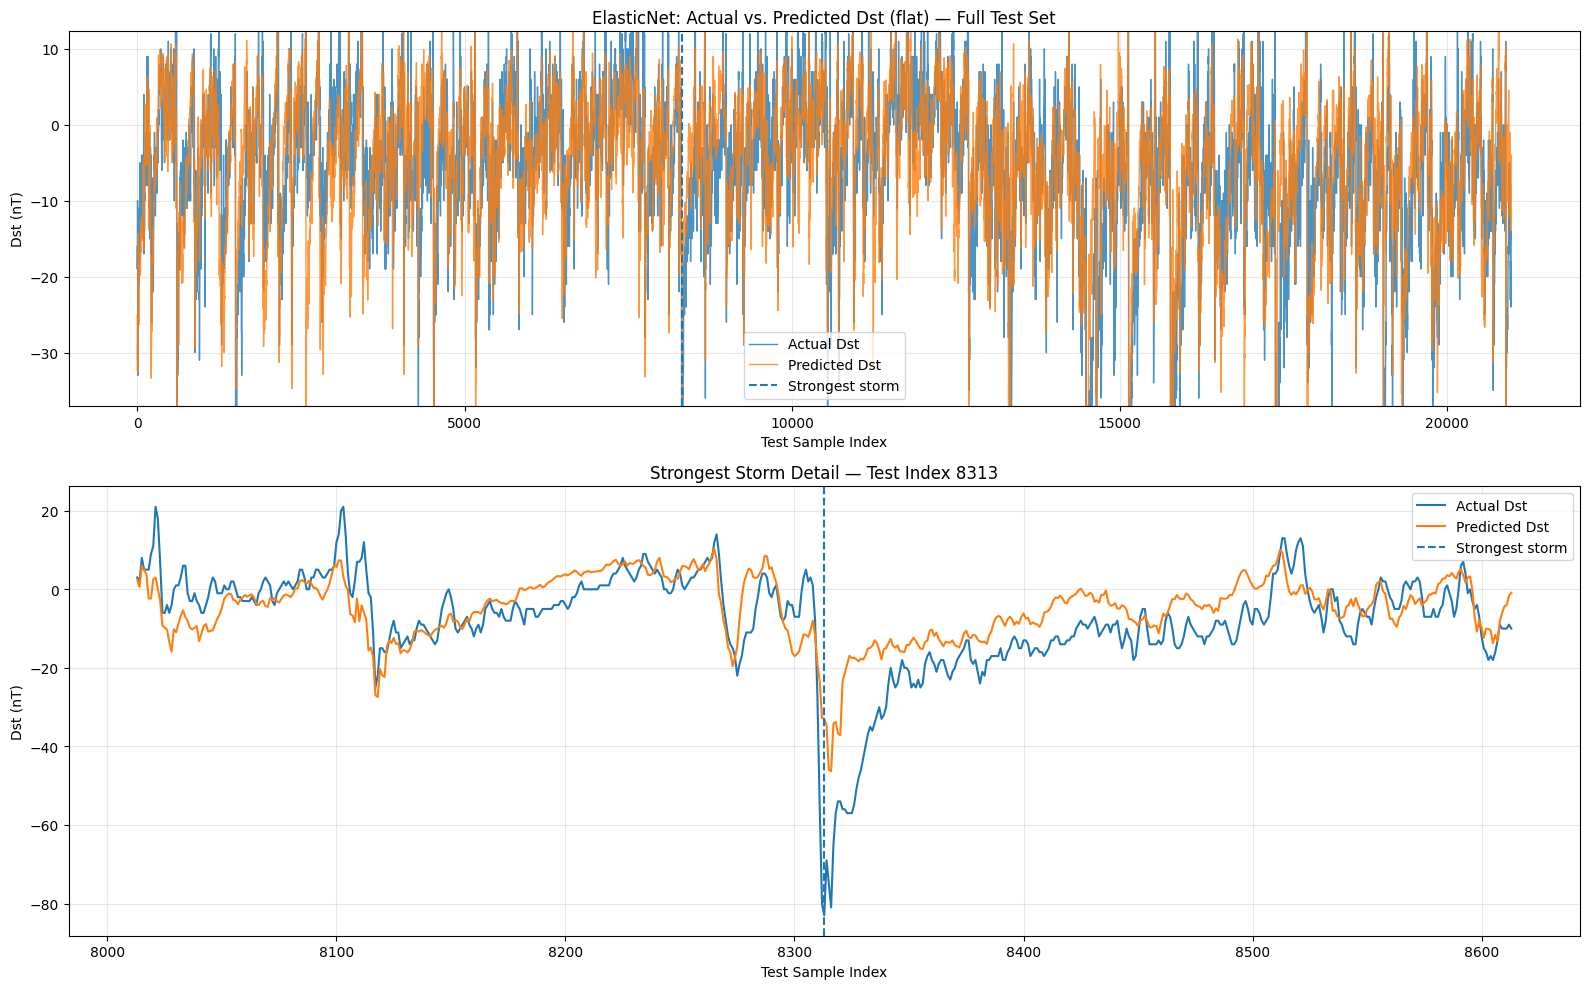

Saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/ElasticNet/figures/elasticnet_01_actual_vs_predicted_flat.png
Strongest storm test index: 8313
Actual Dst at strongest storm: -83.00 nT


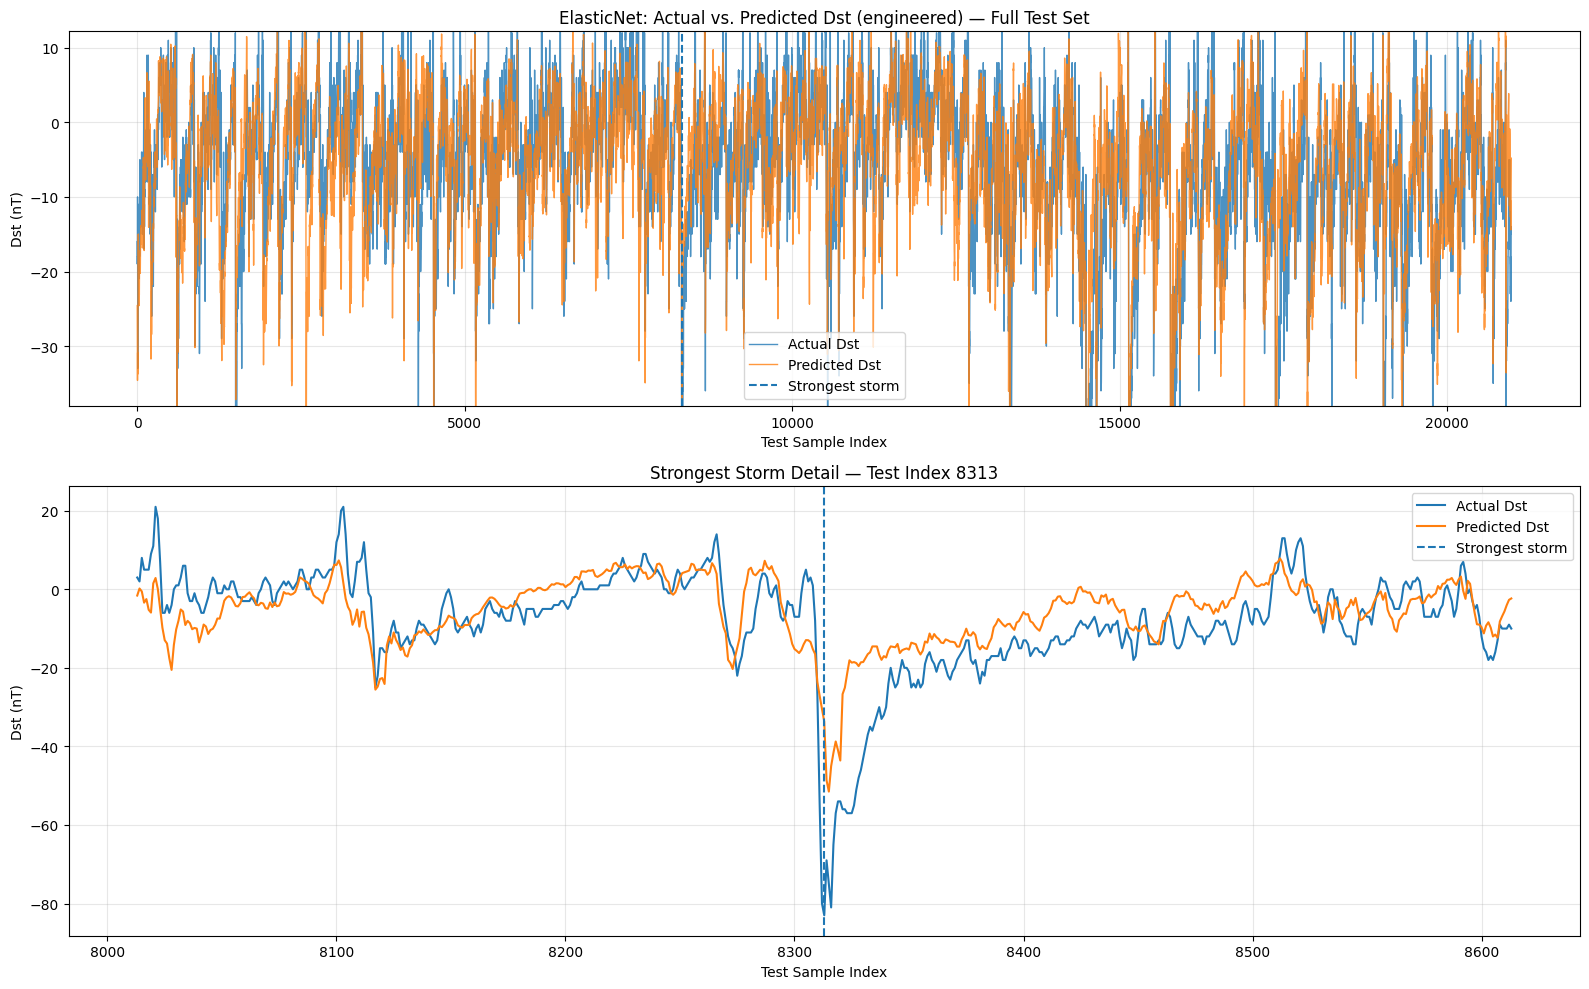

Saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/ElasticNet/figures/elasticnet_01_actual_vs_predicted_engineered.png
Strongest storm test index: 8313
Actual Dst at strongest storm: -83.00 nT

Cell 8 completed successfully.


In [8]:
# Cell 8: ElasticNet — Actual vs. Predicted Dst

def plot_actual_vs_predicted(y_true, y_pred, representation):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    assert len(y_true) == len(y_pred), (
        "Actual and predicted arrays have different lengths."
    )

    # Locate the strongest storm using actual test targets.
    storm_index = int(np.argmin(y_true))

    # Zoom around the strongest storm.
    window = 300
    start_index = max(0, storm_index - window)
    end_index = min(len(y_true), storm_index + window + 1)

    # Use central 98% of values for overview plot limits.
    combined_values = np.concatenate([y_true, y_pred])
    lower_limit, upper_limit = np.percentile(
        combined_values, [1, 99]
    )

    fig, axes = plt.subplots(
        2,
        1,
        figsize=(16, 10),
        gridspec_kw={"height_ratios": [1, 1.2]},
    )

    # --------------------------------------------------------
    # 1. Full test-set overview
    # --------------------------------------------------------
    axes[0].plot(
        y_true,
        label="Actual Dst",
        linewidth=1,
        alpha=0.8,
    )
    axes[0].plot(
        y_pred,
        label="Predicted Dst",
        linewidth=1,
        alpha=0.8,
    )
    axes[0].axvline(
        storm_index,
        linestyle="--",
        linewidth=1.5,
        label="Strongest storm",
    )

    axes[0].set_ylim(lower_limit, upper_limit)
    axes[0].set_title(
        f"ElasticNet: Actual vs. Predicted Dst "
        f"({representation}) — Full Test Set"
    )
    axes[0].set_xlabel("Test Sample Index")
    axes[0].set_ylabel("Dst (nT)")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # --------------------------------------------------------
    # 2. Zoomed strongest-storm interval
    # --------------------------------------------------------
    indices = np.arange(start_index, end_index)

    axes[1].plot(
        indices,
        y_true[start_index:end_index],
        label="Actual Dst",
        linewidth=1.5,
    )
    axes[1].plot(
        indices,
        y_pred[start_index:end_index],
        label="Predicted Dst",
        linewidth=1.5,
    )
    axes[1].axvline(
        storm_index,
        linestyle="--",
        linewidth=1.5,
        label="Strongest storm",
    )

    axes[1].set_title(
        f"Strongest Storm Detail — Test Index {storm_index}"
    )
    axes[1].set_xlabel("Test Sample Index")
    axes[1].set_ylabel("Dst (nT)")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    fig.tight_layout()

    output_path = (
        FIGURES_PATH
        / f"elasticnet_01_actual_vs_predicted_{representation}.png"
    )

    fig.savefig(
        output_path,
        dpi=FIGURE_DPI,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

    print(f"Saved: {output_path}")
    print(f"Strongest storm test index: {storm_index}")
    print(
        f"Actual Dst at strongest storm: "
        f"{y_true[storm_index]:.2f} nT"
    )


# Flat representation
plot_actual_vs_predicted(
    y_test_flat,
    flat_predictions,
    "flat",
)

# Engineered representation
plot_actual_vs_predicted(
    y_test_eng,
    engineered_predictions,
    "engineered",
)

print("\nCell 8 completed successfully.")

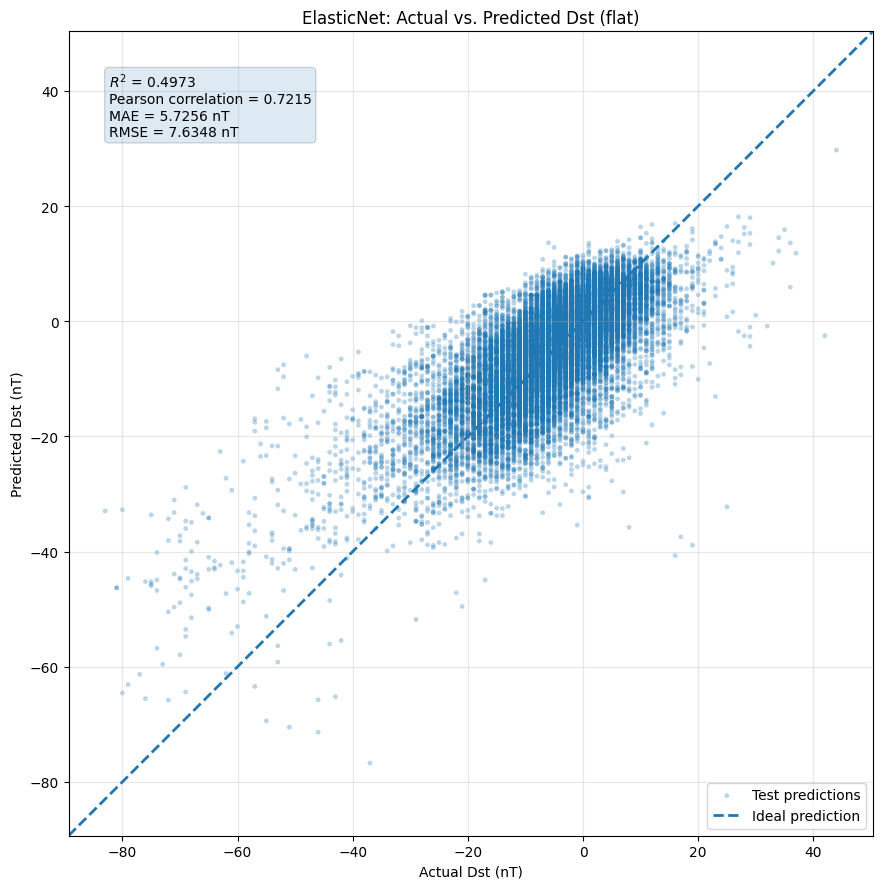

Saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/ElasticNet/figures/elasticnet_02_prediction_scatter_flat.png


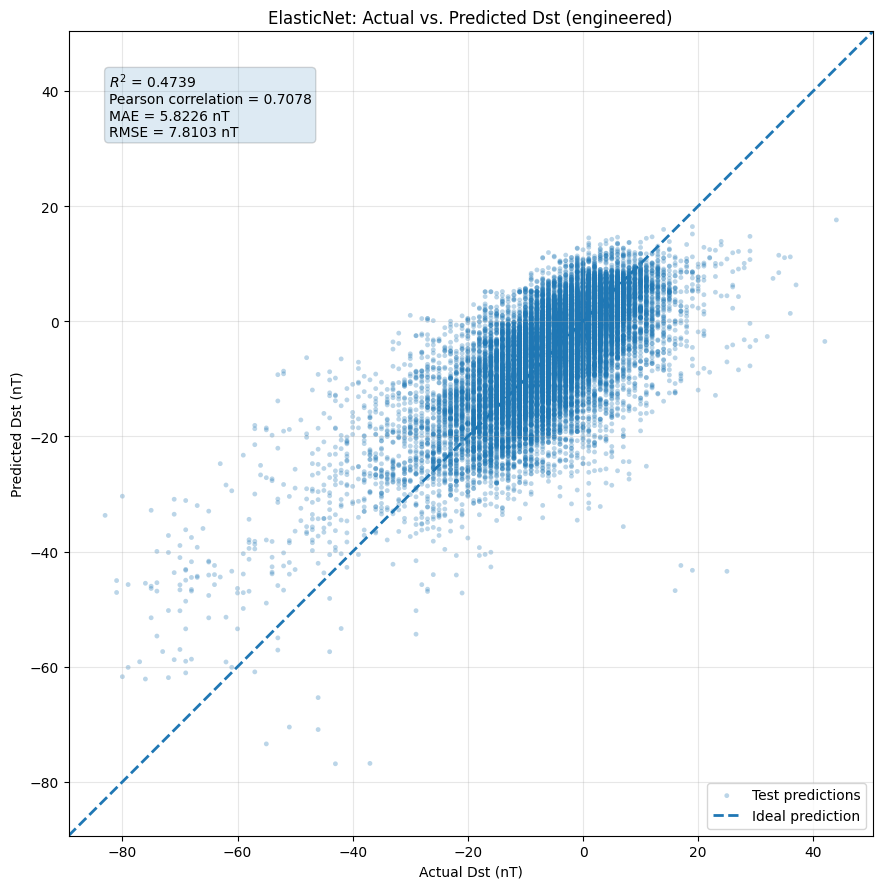

Saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/ElasticNet/figures/elasticnet_02_prediction_scatter_engineered.png

Cell 9 completed successfully.


In [9]:
# Cell 9: ElasticNet — Prediction Scatter Plots

def plot_prediction_scatter(y_true, y_pred, metrics, representation):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    fig, ax = plt.subplots(figsize=(9, 9))

    ax.scatter(
        y_true,
        y_pred,
        s=12,
        alpha=0.3,
        edgecolors="none",
        label="Test predictions",
    )

    lower = min(float(np.min(y_true)), float(np.min(y_pred)))
    upper = max(float(np.max(y_true)), float(np.max(y_pred)))
    padding = max((upper - lower) * 0.05, 2)

    axis_min = lower - padding
    axis_max = upper + padding

    # Ideal prediction line.
    ax.plot(
        [axis_min, axis_max],
        [axis_min, axis_max],
        linestyle="--",
        linewidth=2,
        label="Ideal prediction",
    )

    ax.set_xlim(axis_min, axis_max)
    ax.set_ylim(axis_min, axis_max)
    ax.set_aspect("equal", adjustable="box")

    ax.set_title(
        f"ElasticNet: Actual vs. Predicted Dst ({representation})"
    )
    ax.set_xlabel("Actual Dst (nT)")
    ax.set_ylabel("Predicted Dst (nT)")

    annotation = (
        f"$R^2$ = {metrics['R2']:.4f}\n"
        f"Pearson correlation = "
        f"{metrics['Pearson_Correlation']:.4f}\n"
        f"MAE = {metrics['MAE']:.4f} nT\n"
        f"RMSE = {metrics['RMSE']:.4f} nT"
    )

    ax.text(
        0.05,
        0.95,
        annotation,
        transform=ax.transAxes,
        verticalalignment="top",
        bbox={"boxstyle": "round", "alpha": 0.15},
    )

    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)
    fig.tight_layout()

    output_path = (
        FIGURES_PATH
        / f"elasticnet_02_prediction_scatter_{representation}.png"
    )

    fig.savefig(output_path, dpi=FIGURE_DPI, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved: {output_path}")


# Flat representation
plot_prediction_scatter(
    y_test_flat,
    flat_predictions,
    flat_metrics,
    "flat",
)

# Engineered representation
plot_prediction_scatter(
    y_test_eng,
    engineered_predictions,
    engineered_metrics,
    "engineered",
)

print("\nCell 9 completed successfully.")

Flat representation — RMSE by Dst intensity:


,dst_intensity_bin,sample_count,RMSE
0,≤ -60,73,26.9995
1,"(-60, -40]",188,21.3759
2,"(-40, -20]",1441,11.3235
3,"(-20, 0]",13681,6.5064
4,> 0,5596,7.5601



Engineered representation — RMSE by Dst intensity:


,dst_intensity_bin,sample_count,RMSE
0,≤ -60,73,26.0110
1,"(-60, -40]",188,20.8787
2,"(-40, -20]",1441,10.9662
3,"(-20, 0]",13681,6.5441
4,> 0,5596,8.3397


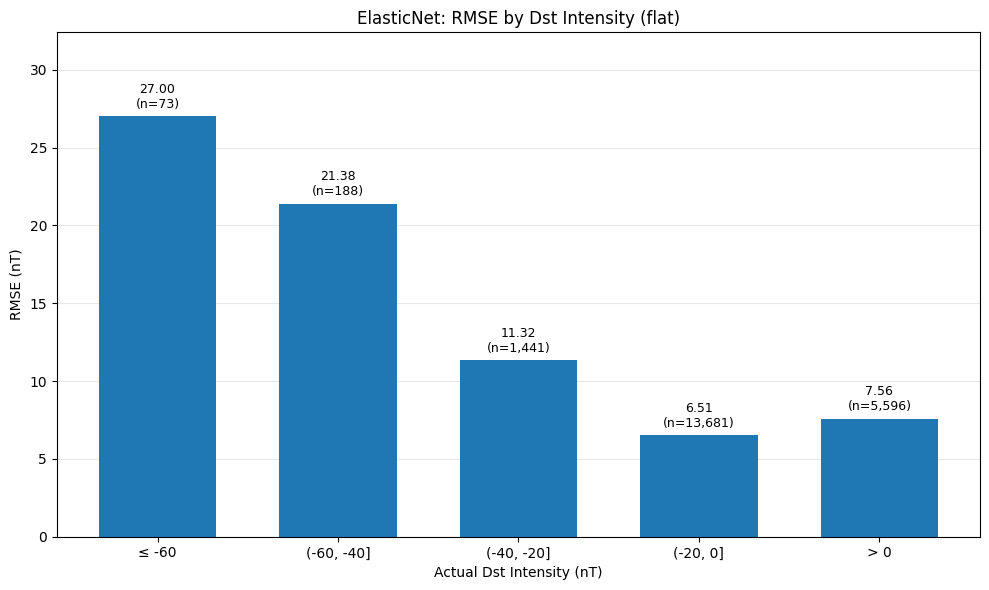

Saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/ElasticNet/figures/elasticnet_03_rmse_by_dst_intensity_flat.png


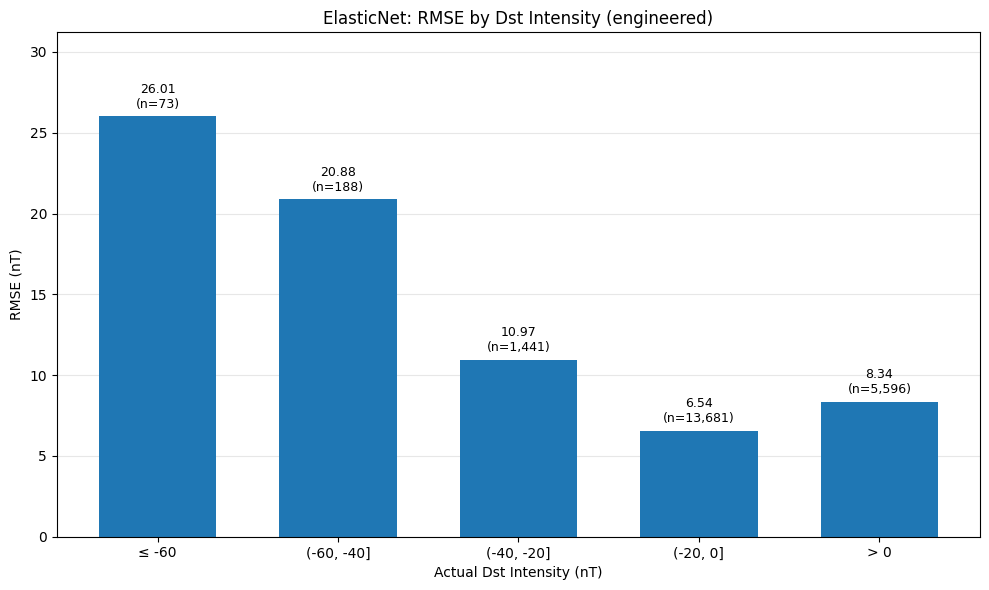

Saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/ElasticNet/figures/elasticnet_03_rmse_by_dst_intensity_engineered.png

Cell 10 completed successfully.


In [12]:
# Cell 10: ElasticNet — RMSE by Dst Intensity

DST_BINS = [
    ("≤ -60", lambda y: y <= -60),
    ("(-60, -40]", lambda y: (y > -60) & (y <= -40)),
    ("(-40, -20]", lambda y: (y > -40) & (y <= -20)),
    ("(-20, 0]", lambda y: (y > -20) & (y <= 0)),
    ("> 0", lambda y: y > 0),
]


def calculate_rmse_by_intensity(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    results = []

    for bin_name, condition in DST_BINS:
        mask = condition(y_true)
        sample_count = int(np.sum(mask))

        if sample_count > 0:
            rmse = float(
                np.sqrt(
                    mean_squared_error(
                        y_true[mask],
                        y_pred[mask],
                    )
                )
            )
        else:
            rmse = np.nan

        results.append({
            "dst_intensity_bin": bin_name,
            "sample_count": sample_count,
            "RMSE": rmse,
        })

    return pd.DataFrame(results)


def plot_rmse_by_intensity(results, representation):
    fig, ax = plt.subplots(figsize=(10, 6))

    labels = results["dst_intensity_bin"].tolist()
    values = results["RMSE"].to_numpy(dtype=float)
    counts = results["sample_count"].to_numpy(dtype=int)

    positions = np.arange(len(labels))
    valid = np.isfinite(values)

    bars = ax.bar(
        positions[valid],
        values[valid],
        width=0.65,
    )

    ax.set_xticks(positions)
    ax.set_xticklabels(labels)
    ax.set_title(
        f"ElasticNet: RMSE by Dst Intensity ({representation})"
    )
    ax.set_xlabel("Actual Dst Intensity (nT)")
    ax.set_ylabel("RMSE (nT)")
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

    if np.any(valid):
        ax.set_ylim(0, max(values[valid]) * 1.2)

    for bar, position in zip(bars, np.flatnonzero(valid)):
        ax.annotate(
            f"{values[position]:.2f}\n(n={counts[position]:,})",
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
        )

    for position in np.flatnonzero(~valid):
        ax.text(
            position,
            0.02,
            "No samples",
            transform=ax.get_xaxis_transform(),
            ha="center",
            va="bottom",
            fontsize=9,
        )

    fig.tight_layout()

    output_path = (
        FIGURES_PATH
        / f"elasticnet_03_rmse_by_dst_intensity_{representation}.png"
    )

    fig.savefig(output_path, dpi=FIGURE_DPI, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved: {output_path}")


# Calculate intensity-wise RMSE on the held-out test set.
elasticnet_flat_intensity = calculate_rmse_by_intensity(
    y_test_flat,
    flat_predictions,
)

elasticnet_engineered_intensity = calculate_rmse_by_intensity(
    y_test_eng,
    engineered_predictions,
)

print("Flat representation — RMSE by Dst intensity:")
display(elasticnet_flat_intensity.round(4))

print("\nEngineered representation — RMSE by Dst intensity:")
display(elasticnet_engineered_intensity.round(4))

# Save both figures.
plot_rmse_by_intensity(elasticnet_flat_intensity, "flat")
plot_rmse_by_intensity(elasticnet_engineered_intensity, "engineered")

# Save numerical results for later comparison.
elasticnet_flat_intensity.to_csv(
    RESULTS_PATH / "elasticnet_flat_rmse_by_dst_intensity.csv",
    index=False,
)

elasticnet_engineered_intensity.to_csv(
    RESULTS_PATH / "elasticnet_engineered_rmse_by_dst_intensity.csv",
    index=False,
)

print("\nCell 10 completed successfully.")

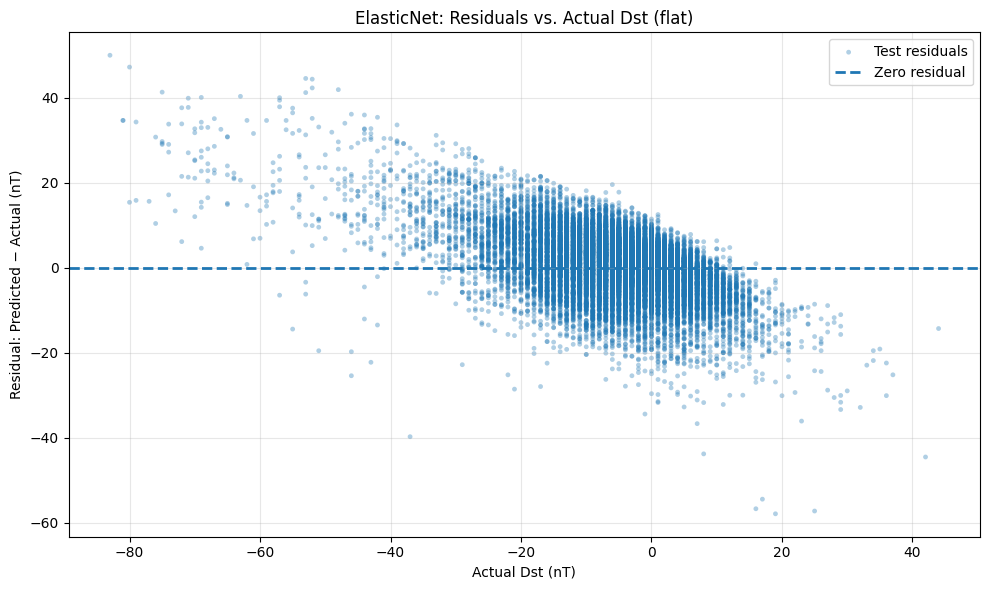

Saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/ElasticNet/figures/elasticnet_04_residuals_vs_actual_flat.png
Mean residual: 0.6180 nT
Residual standard deviation: 7.6098 nT



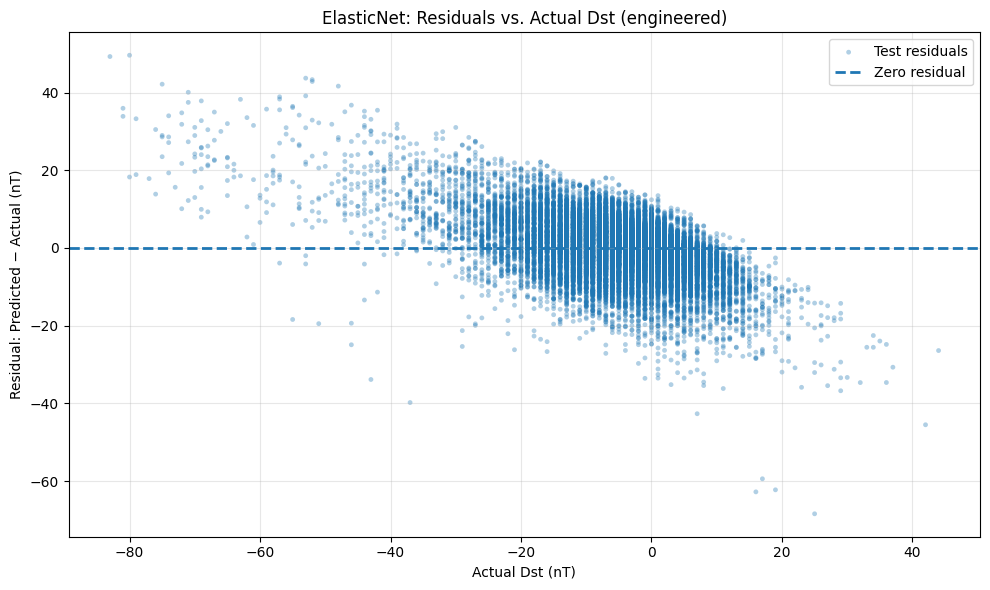

Saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/ElasticNet/figures/elasticnet_04_residuals_vs_actual_engineered.png
Mean residual: -0.0307 nT
Residual standard deviation: 7.8102 nT

Cell 11 completed successfully.


In [13]:
# Cell 11: ElasticNet — Residuals vs. Actual Dst

def plot_residuals_vs_actual(y_true, y_pred, representation):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    residuals = y_pred - y_true

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.scatter(
        y_true,
        residuals,
        s=12,
        alpha=0.35,
        edgecolors="none",
        label="Test residuals",
    )

    ax.axhline(
        y=0,
        linestyle="--",
        linewidth=2,
        label="Zero residual",
    )

    ax.set_title(
        f"ElasticNet: Residuals vs. Actual Dst ({representation})"
    )
    ax.set_xlabel("Actual Dst (nT)")
    ax.set_ylabel("Residual: Predicted − Actual (nT)")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()

    output_path = (
        FIGURES_PATH
        / f"elasticnet_04_residuals_vs_actual_{representation}.png"
    )

    fig.savefig(output_path, dpi=FIGURE_DPI, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved: {output_path}")
    print(f"Mean residual: {np.mean(residuals):.4f} nT")
    print(f"Residual standard deviation: {np.std(residuals):.4f} nT")


# Flat representation
plot_residuals_vs_actual(
    y_test_flat,
    flat_predictions,
    "flat",
)

print()

# Engineered representation
plot_residuals_vs_actual(
    y_test_eng,
    engineered_predictions,
    "engineered",
)

print("\nCell 11 completed successfully.")

In [14]:
# Cell 12: Save ElasticNet Results and Verify Artifacts

# ------------------------------------------------------------
# 1. Create output directories
# ------------------------------------------------------------

RESULTS_PATH.mkdir(parents=True, exist_ok=True)
FIGURES_PATH.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Save selected models and fitted scalers
# ------------------------------------------------------------

flat_model_path = RESULTS_PATH / "elasticnet_flat_model.joblib"
engineered_model_path = RESULTS_PATH / "elasticnet_engineered_model.joblib"

flat_scaler_path = RESULTS_PATH / "elasticnet_flat_scaler.joblib"
engineered_scaler_path = RESULTS_PATH / "elasticnet_engineered_scaler.joblib"

joblib.dump(elasticnet_flat_model, flat_model_path)
joblib.dump(elasticnet_engineered_model, engineered_model_path)

joblib.dump(flat_scaler, flat_scaler_path)
joblib.dump(engineered_scaler, engineered_scaler_path)

print("Selected ElasticNet models and fitted scalers saved.")


# ------------------------------------------------------------
# 3. Calculate and save validation metrics
# ------------------------------------------------------------

flat_validation_metrics = evaluate_regression(
    y_val_flat,
    flat_validation_predictions,
)

engineered_validation_metrics = evaluate_regression(
    y_val_eng,
    engineered_validation_predictions,
)

validation_metrics_df = pd.DataFrame([
    {
        "Representation": "Flat",
        **flat_validation_metrics,
    },
    {
        "Representation": "Engineered",
        **engineered_validation_metrics,
    },
])

validation_metrics_path = (
    RESULTS_PATH / "elasticnet_validation_metrics.csv"
)

validation_metrics_df.to_csv(
    validation_metrics_path,
    index=False,
)

np.save(
    RESULTS_PATH / "elasticnet_flat_validation_predictions.npy",
    flat_validation_predictions,
)

np.save(
    RESULTS_PATH / "elasticnet_engineered_validation_predictions.npy",
    engineered_validation_predictions,
)

print("\nValidation metrics:")
display(validation_metrics_df.round(4))


# ------------------------------------------------------------
# 4. Save held-out test metrics and predictions
# ------------------------------------------------------------

test_metrics_df = pd.DataFrame([
    {"Representation": "Flat", **flat_metrics},
    {"Representation": "Engineered", **engineered_metrics},
])

test_metrics_csv_path = (
    RESULTS_PATH / "elasticnet_test_metrics.csv"
)

test_metrics_json_path = (
    RESULTS_PATH / "elasticnet_test_metrics.json"
)

test_metrics_df.to_csv(
    test_metrics_csv_path,
    index=False,
)

with open(test_metrics_json_path, "w") as f:
    json.dump(
        {
            "flat": flat_metrics,
            "engineered": engineered_metrics,
        },
        f,
        indent=4,
        allow_nan=True,
    )

np.save(
    RESULTS_PATH / "elasticnet_flat_test_predictions.npy",
    flat_predictions,
)

np.save(
    RESULTS_PATH / "elasticnet_engineered_test_predictions.npy",
    engineered_predictions,
)

test_predictions_df = pd.DataFrame({
    "actual_dst": y_test_flat,
    "flat_predicted_dst": flat_predictions,
    "engineered_predicted_dst": engineered_predictions,
})

test_predictions_path = (
    RESULTS_PATH / "elasticnet_test_predictions.csv"
)

test_predictions_df.to_csv(
    test_predictions_path,
    index=False,
)

print("\nHeld-out test metrics:")
display(test_metrics_df.round(4))

print("\nSaved test metrics and predictions.")


# ------------------------------------------------------------
# 5. Save hyperparameter search tables
# ------------------------------------------------------------

flat_search_path = (
    RESULTS_PATH / "elasticnet_flat_alpha_search.csv"
)

engineered_search_path = (
    RESULTS_PATH / "elasticnet_engineered_alpha_search.csv"
)

flat_validation_results_df.to_csv(
    flat_search_path,
    index=False,
)

engineered_validation_results_df.to_csv(
    engineered_search_path,
    index=False,
)


# ------------------------------------------------------------
# 6. Save intensity-wise RMSE results
# ------------------------------------------------------------

flat_intensity_path = (
    RESULTS_PATH / "elasticnet_flat_rmse_by_dst_intensity.csv"
)

engineered_intensity_path = (
    RESULTS_PATH / "elasticnet_engineered_rmse_by_dst_intensity.csv"
)

elasticnet_flat_intensity.to_csv(
    flat_intensity_path,
    index=False,
)

elasticnet_engineered_intensity.to_csv(
    engineered_intensity_path,
    index=False,
)


# ------------------------------------------------------------
# 7. Record model, scaler, and artifact sizes
# ------------------------------------------------------------

model_information = {}

model_entries = [
    (
        "flat",
        flat_model_path,
        flat_scaler_path,
        elasticnet_flat_model,
        X_train_flat.shape[1],
        best_flat_alpha,
        best_flat_l1_ratio,
        flat_training_duration,
        flat_tuning_duration,
        flat_nonzero_coefficients,
        flat_zero_coefficients,
    ),
    (
        "engineered",
        engineered_model_path,
        engineered_scaler_path,
        elasticnet_engineered_model,
        X_train_eng.shape[1],
        best_engineered_alpha,
        best_engineered_l1_ratio,
        engineered_training_duration,
        engineered_tuning_duration,
        engineered_nonzero_coefficients,
        engineered_zero_coefficients,
    ),
]

for (
    representation,
    model_path,
    scaler_path,
    model,
    feature_count,
    selected_alpha,
    selected_l1_ratio,
    selected_fit_time,
    total_search_time,
    nonzero_count,
    zero_count,
) in model_entries:

    model_size_bytes = model_path.stat().st_size
    scaler_size_bytes = scaler_path.stat().st_size

    model_information[representation] = {
        "model_file": str(model_path),
        "scaler_file": str(scaler_path),
        "model_size_bytes": int(model_size_bytes),
        "model_size_mb": float(model_size_bytes / (1024 ** 2)),
        "scaler_size_bytes": int(scaler_size_bytes),
        "scaler_size_mb": float(scaler_size_bytes / (1024 ** 2)),
        "model_plus_scaler_size_mb": float(
            (model_size_bytes + scaler_size_bytes) / (1024 ** 2)
        ),
        "feature_count": int(feature_count),
        "coefficient_count": int(model.coef_.size),
        "nonzero_coefficients": int(nonzero_count),
        "zero_coefficients": int(zero_count),
        "selected_alpha": float(selected_alpha),
        "selected_l1_ratio": float(selected_l1_ratio),
        "selected_fit_time_seconds": float(selected_fit_time),
        "total_hyperparameter_search_seconds": float(total_search_time),
        "n_iter": int(model.n_iter_),
        "max_iter": int(MAX_ITER),
        "converged_within_max_iter": bool(
            int(model.n_iter_) < MAX_ITER
        ),
    }

model_information_path = (
    RESULTS_PATH / "elasticnet_model_information.json"
)

with open(model_information_path, "w") as f:
    json.dump(model_information, f, indent=4)

print("\nElasticNet model information:")
display(pd.DataFrame([
    {"Representation": representation.title(), **details}
    for representation, details in model_information.items()
]).round(5))


# ------------------------------------------------------------
# 8. Save inference benchmark results
# ------------------------------------------------------------

inference_json_path = (
    RESULTS_PATH / "elasticnet_inference_timing.json"
)

inference_csv_path = (
    RESULTS_PATH / "elasticnet_inference_timing.csv"
)

with open(inference_json_path, "w") as f:
    json.dump(inference_results, f, indent=4)

inference_summary.to_csv(
    inference_csv_path,
    index=False,
)


# ------------------------------------------------------------
# 9. Save complete experiment metrics
# ------------------------------------------------------------

complete_metrics = {
    "model_name": "ElasticNet Regression",
    "validation_metrics": {
        "flat": flat_validation_metrics,
        "engineered": engineered_validation_metrics,
    },
    "test_metrics": {
        "flat": flat_metrics,
        "engineered": engineered_metrics,
    },
    "hyperparameter_selection": {
        "selection_metric": "Validation RMSE",
        "flat": {
            "selected_alpha": float(best_flat_alpha),
            "selected_l1_ratio": float(best_flat_l1_ratio),
            "best_validation_rmse": float(best_flat_val_rmse),
        },
        "engineered": {
            "selected_alpha": float(best_engineered_alpha),
            "selected_l1_ratio": float(best_engineered_l1_ratio),
            "best_validation_rmse": float(best_engineered_val_rmse),
        },
    },
    "model_information": model_information,
    "inference_benchmark": {
        "timing_scope": (
            "Model prediction on pre-scaled test features; "
            "scaler transformation excluded."
        ),
        "flat": flat_inference,
        "engineered": engineered_inference,
    },
}

complete_metrics_path = (
    RESULTS_PATH / "elasticnet_complete_metrics.json"
)

with open(complete_metrics_path, "w") as f:
    json.dump(complete_metrics, f, indent=4, allow_nan=True)


# ------------------------------------------------------------
# 10. Save experiment metadata
# ------------------------------------------------------------

run_metadata = {
    "model_name": MODEL_NAME,
    "model_family": "ElasticNet Regression",
    "random_state": int(RANDOM_STATE),
    "scikit_learn_version": sklearn.__version__,
    "python_version": platform.python_version(),
    "configuration": elasticnet_config,
    "data": {
        "training_samples": int(len(y_train_flat)),
        "validation_samples": int(len(y_val_flat)),
        "test_samples": int(len(y_test_flat)),
        "flat_features": int(X_train_flat.shape[1]),
        "engineered_features": int(X_train_eng.shape[1]),
        "target_splits_match": True,
    },
    "scaling": (
        "StandardScaler fitted on training data only; "
        "validation and test data transformed using that fitted scaler."
    ),
    "model_selection": "Lowest validation RMSE",
    "selected_hyperparameters": {
        "flat": {
            "alpha": float(best_flat_alpha),
            "l1_ratio": float(best_flat_l1_ratio),
        },
        "engineered": {
            "alpha": float(best_engineered_alpha),
            "l1_ratio": float(best_engineered_l1_ratio),
        },
    },
    "search_convergence": {
        "flat_candidates_reaching_max_iter": int(
            (flat_validation_results_df["n_iter"] >= MAX_ITER).sum()
        ),
        "engineered_candidates_reaching_max_iter": int(
            (
                engineered_validation_results_df["n_iter"] >= MAX_ITER
            ).sum()
        ),
        "interpretation": (
            "Candidates reaching max_iter are flagged for review. "
            "Their recorded validation scores are not proof of convergence."
        ),
    },
    "inference_timing": {
        "warmup_runs": int(WARMUP_RUNS),
        "timed_repetitions": int(INFERENCE_REPEATS),
        "includes_scaling": False,
    },
    "test_metrics": {
        "flat": flat_metrics,
        "engineered": engineered_metrics,
    },
}

metadata_path = (
    RESULTS_PATH / "elasticnet_experiment_metadata.json"
)

with open(metadata_path, "w") as f:
    json.dump(run_metadata, f, indent=4, allow_nan=True)

print(f"\nExperiment metadata saved: {metadata_path}")


# ------------------------------------------------------------
# 11. Verify expected artifacts
# ------------------------------------------------------------

expected_result_files = [
    flat_model_path,
    engineered_model_path,
    flat_scaler_path,
    engineered_scaler_path,

    RESULTS_PATH / "elasticnet_configuration.json",
    flat_search_path,
    engineered_search_path,

    RESULTS_PATH / "elasticnet_flat_validation_predictions.npy",
    RESULTS_PATH / "elasticnet_engineered_validation_predictions.npy",
    validation_metrics_path,

    RESULTS_PATH / "elasticnet_flat_test_predictions.npy",
    RESULTS_PATH / "elasticnet_engineered_test_predictions.npy",
    test_predictions_path,
    test_metrics_csv_path,
    test_metrics_json_path,

    flat_intensity_path,
    engineered_intensity_path,

    inference_json_path,
    inference_csv_path,
    model_information_path,
    complete_metrics_path,
    metadata_path,
]

expected_figure_files = [
    FIGURES_PATH / "elasticnet_01_actual_vs_predicted_flat.png",
    FIGURES_PATH / "elasticnet_01_actual_vs_predicted_engineered.png",
    FIGURES_PATH / "elasticnet_02_prediction_scatter_flat.png",
    FIGURES_PATH / "elasticnet_02_prediction_scatter_engineered.png",
    FIGURES_PATH / "elasticnet_03_rmse_by_dst_intensity_flat.png",
    FIGURES_PATH / "elasticnet_03_rmse_by_dst_intensity_engineered.png",
    FIGURES_PATH / "elasticnet_04_residuals_vs_actual_flat.png",
    FIGURES_PATH / "elasticnet_04_residuals_vs_actual_engineered.png",
]

verification_results = []

for artifact_path in expected_result_files + expected_figure_files:
    exists = artifact_path.exists()
    size_bytes = artifact_path.stat().st_size if exists else None

    verification_results.append({
        "Artifact": str(artifact_path.relative_to(RESULTS_PATH)),
        "Exists": exists,
        "Size (MB)": (
            round(size_bytes / (1024 ** 2), 6)
            if size_bytes is not None
            else None
        ),
    })

verification_df = pd.DataFrame(verification_results)

print("\nArtifact verification:")
display(verification_df)

missing_artifacts = verification_df.loc[
    ~verification_df["Exists"], "Artifact"
].tolist()

if missing_artifacts:
    print("\nWARNING: Expected artifacts are missing:")
    for artifact in missing_artifacts:
        print(f" - {artifact}")
else:
    print(
        f"\nAll {len(expected_result_files) + len(expected_figure_files)} "
        "expected artifacts are present."
    )

print(f"\nResults directory: {RESULTS_PATH}")
print(f"Figures directory: {FIGURES_PATH}")
print("\nCell 12 completed.")

Selected ElasticNet models and fitted scalers saved.

Validation metrics:


,Representation,MAE,RMSE,R2,Pearson_Correlation,Median_Absolute_Error,Explained_Variance,Maximum_Absolute_Error
0,Flat,6.8303,9.1393,0.5193,0.7333,5.4418,0.5218,86.2780
1,Engineered,6.8857,9.2524,0.5074,0.7233,5.4693,0.5079,80.4326



Held-out test metrics:


,Representation,MAE,RMSE,R2,Pearson_Correlation,Median_Absolute_Error,Explained_Variance,Maximum_Absolute_Error
0,Flat,5.7256,7.6348,0.4973,0.7215,4.4922,0.5006,57.8873
1,Engineered,5.8226,7.8103,0.4739,0.7078,4.5072,0.4739,68.4273



Saved test metrics and predictions.

ElasticNet model information:


,Representation,model_file,scaler_file,model_size_bytes,model_size_mb,scaler_size_bytes,scaler_size_mb,model_plus_scaler_size_mb,feature_count,coefficient_count,nonzero_coefficients,zero_coefficients,selected_alpha,selected_l1_ratio,selected_fit_time_seconds,total_hyperparameter_search_seconds,n_iter,max_iter,converged_within_max_iter
0,Flat,/content/drive/MyDrive/Solar_Wind_Project/ML/L...,/content/drive/MyDrive/Solar_Wind_Project/ML/L...,4672,0.00446,24807,0.02366,0.02811,1008,1008,173,835,1.0,0.9,2.26070,901.81892,35,2000,True
1,Engineered,/content/drive/MyDrive/Solar_Wind_Project/ML/L...,/content/drive/MyDrive/Solar_Wind_Project/ML/L...,1072,0.00102,3303,0.00315,0.00417,112,112,92,20,1.0,0.1,0.23948,88.90262,16,2000,True



Experiment metadata saved: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/ElasticNet/elasticnet_experiment_metadata.json

Artifact verification:


,Artifact,Exists,Size (MB)
0,elasticnet_flat_model.joblib,True,0.004456
1,elasticnet_engineered_model.joblib,True,0.001022
2,elasticnet_flat_scaler.joblib,True,0.023658
3,elasticnet_engineered_scaler.joblib,True,0.003150
4,elasticnet_configuration.json,True,0.000449
5,elasticnet_flat_alpha_search.csv,True,0.000817
6,elasticnet_engineered_alpha_search.csv,True,0.000816
7,elasticnet_flat_validation_predictions.npy,True,0.080147
8,elasticnet_engineered_validation_predictions.npy,True,0.080147
9,elasticnet_validation_metrics.csv,True,0.000367



All 30 expected artifacts are present.

Results directory: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/ElasticNet
Figures directory: /content/drive/MyDrive/Solar_Wind_Project/ML/Linear/ElasticNet/figures

Cell 12 completed.
